# AI-Powered Sales-to-Production Impact Simulator

## Demola Project Prototype

### Objective

This project demonstrates how a decision made by the Sales Department can impact the Production Department in a manufacturing company.

### Business Question

What happens if Sales offers a discount campaign?

Can we predict:

- Expected customer orders
- Production demand
- Capacity utilization

before the campaign is launched?

# 1. Problem Statement

Manufacturing companies often make decisions within individual departments.

For example:

- Sales focuses on increasing customer orders.
- Production focuses on meeting manufacturing demand efficiently.

When Sales launches a discount campaign, Production may suddenly face increased workload and capacity challenges.

Without visibility across departments, organizations may experience:

- Production bottlenecks
- Resource shortages
- Overtime costs
- Reduced operational efficiency

The goal of this project is to predict production impacts before implementing a sales decision.

# 2. Proposed Solution

We propose an AI-powered decision support system capable of estimating the operational impact of sales decisions.

Workflow:

Discount Offer
↓
Customer Demand Prediction
↓
Order Volume Estimation
↓
Production Impact Analysis
↓
Decision Support

This prototype focuses on understanding the relationship between sales discounts and production demand.

In [1]:
import pandas as pd

df = pd.read_csv("../data/sales_production_data.csv")

df.head()

,discount_percentage,orders_received
0,0,1000
1,1,1020
2,2,1045
3,3,1070
4,4,1090


In [2]:
df

,discount_percentage,orders_received
0,0,1000
1,1,1020
2,2,1045
3,3,1070
4,4,1090
5,5,1120
6,6,1145
7,7,1170
8,8,1200
9,9,1220


In [3]:
import matplotlib.pyplot as plt

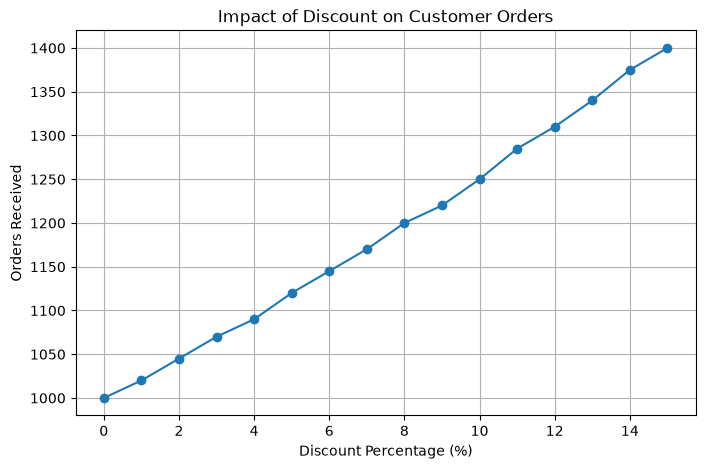

In [4]:
plt.figure(figsize=(8,5))

plt.plot(
    df["discount_percentage"],
    df["orders_received"],
    marker="o"
)

plt.title("Impact of Discount on Customer Orders")
plt.xlabel("Discount Percentage (%)")
plt.ylabel("Orders Received")

plt.grid(True)

plt.show()

In [5]:
print("""
Business Insight:

As discount percentage increases,
customer orders also increase.

This indicates a strong positive relationship
between sales promotions and production demand.
""")


Business Insight:

As discount percentage increases,
customer orders also increase.

This indicates a strong positive relationship
between sales promotions and production demand.



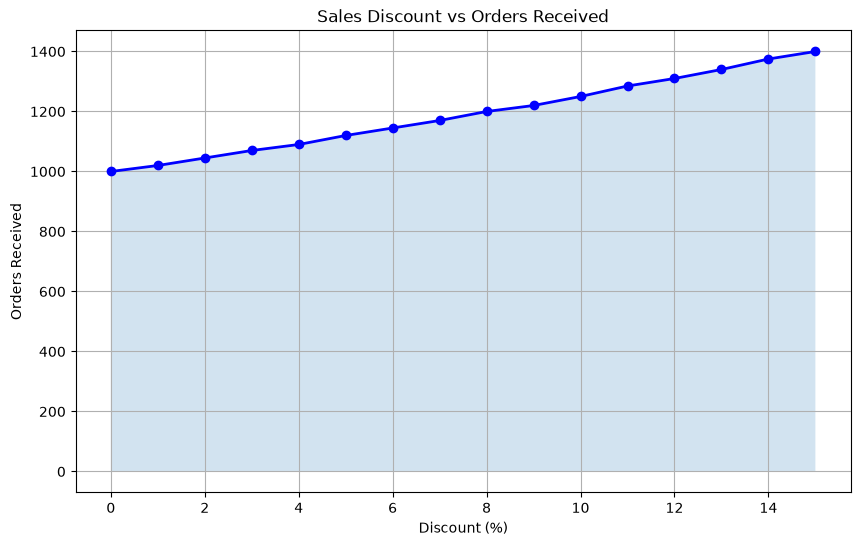

In [6]:
plt.figure(figsize=(10,6))

plt.plot(
    df["discount_percentage"],
    df["orders_received"],
    color="blue",
    marker="o",
    linewidth=2
)

plt.fill_between(
    df["discount_percentage"],
    df["orders_received"],
    alpha=0.2
)

plt.title("Sales Discount vs Orders Received")
plt.xlabel("Discount (%)")
plt.ylabel("Orders Received")
plt.grid(True)

plt.show()

In [7]:
from sklearn.linear_model import LinearRegression

In [8]:
X = df[["discount_percentage"]]

y = df["orders_received"]

In [9]:
model = LinearRegression()

model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[26.9]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['discount_percentage']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,988.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [10]:
predicted_orders = model.predict([[10]])

print(predicted_orders)

[1257.24264706]


/Users/mohosina/Desktop/BME/Next Endevour/Demola/AI_Driven_Decison_Support_System/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [11]:
discount = 10

prediction = model.predict([[discount]])

print(f"If Sales offers a {discount}% discount,")
print(f"expected orders = {int(prediction[0])}")

If Sales offers a 10% discount,
expected orders = 1257


/Users/mohosina/Desktop/BME/Next Endevour/Demola/AI_Driven_Decison_Support_System/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [12]:
predictions = model.predict(X)

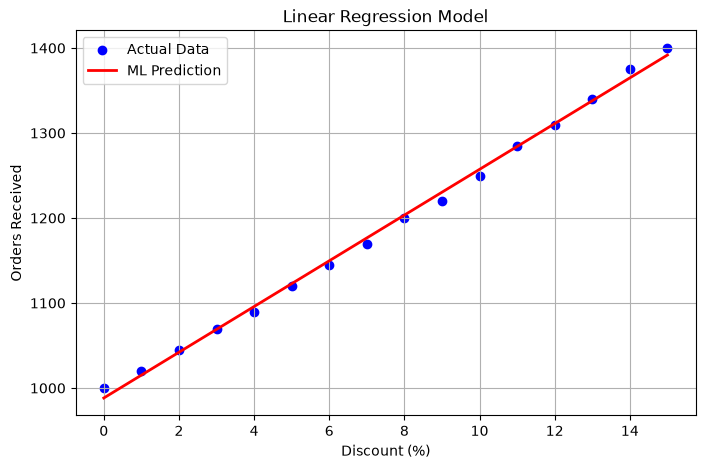

In [13]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["discount_percentage"],
    df["orders_received"],
    color="blue",
    label="Actual Data"
)

plt.plot(
    df["discount_percentage"],
    predictions,
    color="red",
    linewidth=2,
    label="ML Prediction"
)

plt.title("Linear Regression Model")
plt.xlabel("Discount (%)")
plt.ylabel("Orders Received")

plt.legend()

plt.grid(True)

plt.show()

In [17]:
discount = float(input("Enter discount percentage: "))

prediction = model.predict([[discount]])

print(f"\nPredicted Orders: {int(prediction[0])}")


Predicted Orders: 2064


/Users/mohosina/Desktop/BME/Next Endevour/Demola/AI_Driven_Decison_Support_System/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
